In [ ]:
import matplotlib.pyplot as plt # pyplot -> plotting interface
# matplotlib is a library , plt is aliasing
import pandas as pd
import numpy as np





In [ ]:
import pandas as pd

customers = pd.DataFrame({
    "Customer_ID": [101, 102, 103, 104, 105, 106, 107, 108],

    "Name": [
        "Arun", "Meera", "Rahul", "Anjali",
        "Vivek", "Priya", "Kiran", "Sneha"
    ],

    "City": [
        "Kochi", "Chennai", "Kochi", "Bangalore",
        "Kochi", "Chennai", "Bangalore", "Kochi"
    ],

    "Gender": [
        "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female"
    ]
})

orders = pd.DataFrame({
    "Order_ID": [
        1001, 1002, 1003, 1004,
        1005, 1006, 1007, 1008,
        1009, 1010, 1011, 1012
    ],

    "Customer_ID": [
        101, 102, 101, 103,
        104, 105, 106, 102,
        107, 108, 109, 103
    ],

    "Product_ID": [
        "P01", "P02", "P03", "P01",
        "P04", "P02", "P05", "P03",
        "P01", "P05", "P02", "P04"
    ],

    "Order_Date": [
        "2026-01-05", "2026-01-08", "2026-01-15",
        "2026-01-20", "2026-02-03", "2026-02-10",
        "2026-02-18", "2026-03-02",
        "2026-03-10", "2026-03-15", "2026-03-20",
        "2026-03-25"
    ],

    "Quantity": [
        2, 1, 3, 1,
        2, 4, 1, 2,
        1, 3, 2, 1
    ],

    "Payment_Method": [
        "UPI", "Card", "UPI", "Cash",
        "Card", "UPI", "Cash", "Card",
        "UPI", "Card", "UPI", "Cash"
    ]
})

products = pd.DataFrame({
    "Product_ID": [
        "P01", "P02", "P03", "P04", "P05"
    ],

    "Product": [
        "Laptop", "Mouse", "Keyboard",
        "Headphones", "Monitor"
    ],

    "Category": [
        "Electronics", "Accessories", "Accessories",
        "Accessories", "Electronics"
    ],

    "Price": [
        55000, 800, 1500, 2500, 12000
    ]
})

orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])

order_customer = pd.merge(
    orders,
    customers,
    on="Customer_ID",
    how="left"
)

sales = pd.merge(
    order_customer,
    products,
    on="Product_ID",
    how="left"
)

sales["Revenue"] = (
    sales["Quantity"] * sales["Price"]
)

sales["Month"] = (
    sales["Order_Date"].dt.month_name()
)
sales



,Order_ID,Customer_ID,Product_ID,Order_Date,Quantity,Payment_Method,Name,City,Gender,Product,Category,Price,Revenue,Month
0,1001,101,P01,2026-01-05,2,UPI,Arun,Kochi,Male,Laptop,Electronics,55000,110000,January
1,1002,102,P02,2026-01-08,1,Card,Meera,Chennai,Female,Mouse,Accessories,800,800,January
2,1003,101,P03,2026-01-15,3,UPI,Arun,Kochi,Male,Keyboard,Accessories,1500,4500,January
3,1004,103,P01,2026-01-20,1,Cash,Rahul,Kochi,Male,Laptop,Electronics,55000,55000,January
4,1005,104,P04,2026-02-03,2,Card,Anjali,Bangalore,Female,Headphones,Accessories,2500,5000,February
5,1006,105,P02,2026-02-10,4,UPI,Vivek,Kochi,Male,Mouse,Accessories,800,3200,February
6,1007,106,P05,2026-02-18,1,Cash,Priya,Chennai,Female,Monitor,Electronics,12000,12000,February
7,1008,102,P03,2026-03-02,2,Card,Meera,Chennai,Female,Keyboard,Accessories,1500,3000,March
8,1009,107,P01,2026-03-10,1,UPI,Kiran,Bangalore,Male,Laptop,Electronics,55000,55000,March
9,1010,108,P05,2026-03-15,3,Card,Sneha,Kochi,Female,Monitor,Electronics,12000,36000,March


In [ ]:
print(sales.iloc[2,0])

1003


In [ ]:
# # order_customer.isna().sum()
# pd.loc[3]              # row with INDEX LABEL 3
# pd.iloc[3]              # row at POSITION 3 (like a list)
# pd.loc[3, "Salary"]     # row label 3, column "Salary"
# pd.loc[:, "Salary"]     # ALL rows, column "Salary" (: means "everything")
# pd.loc[pd["Salary"]>40000, ["Name","Salary"]]   # condition + specific columns together

In [ ]:
sales.groupby("Category")["Revenue"].sum()

,Revenue
Category,
Accessories,20600
Electronics,268000


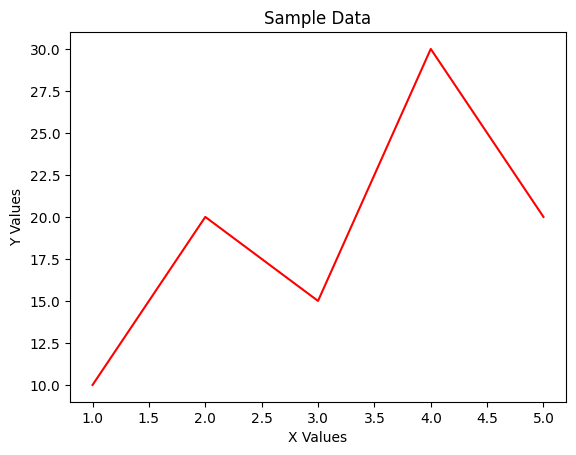

In [ ]:
x = [1,2,3,4,5]
y = [10,20,15,30,20]
plt.plot(x,y, color='red')

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Sample Data")
plt.show() # for viewing

In [ ]:
monthly_sales = sales.groupby("Month")["Revenue"].sum()
monthly_sales

,Revenue
Month,
February,20200
January,170300
March,98100


In [ ]:
month_order = ["January","February","March"]

In [ ]:
monthly_sales = monthly_sales.reindex(month_order)
monthly_sales

,Revenue
Month,
January,170300
February,20200
March,98100


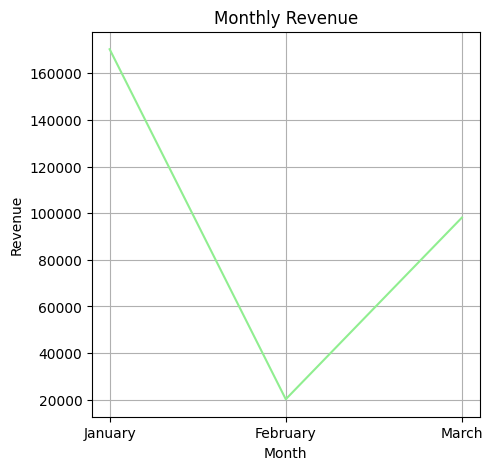

In [ ]:
plt.figure(figsize=(5,5)
)

plt.plot(monthly_sales.index,monthly_sales.values, color='lightgreen') # plot used for line chart ( time series data )
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid()

plt.title("Monthly Revenue")
plt.show()

In [ ]:
category_sales = sales.groupby("Category")["Revenue"].sum()
category_sales

,Revenue
Category,
Accessories,20600
Electronics,268000


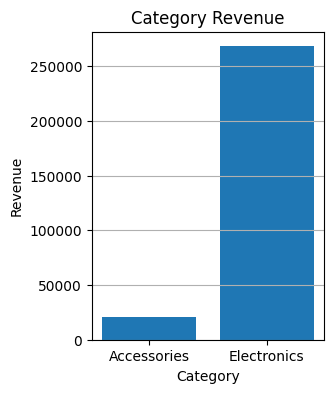

In [ ]:
plt.figure(figsize=(3,4))
plt.bar(category_sales.index,category_sales.values) # bar is used to create the bar chart ( Comparison )
plt.title("Category Revenue")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.grid(axis='y') # only y grid is needed for correct



plt.show()

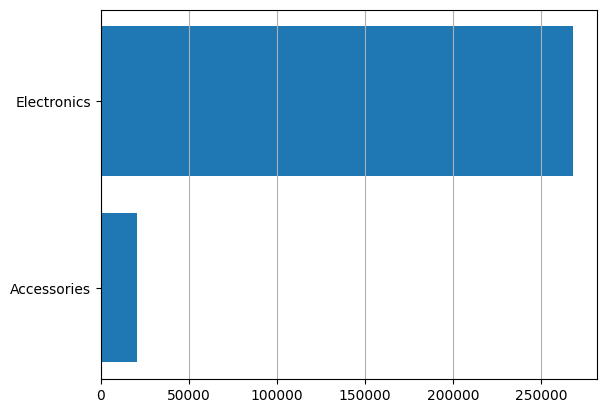

In [ ]:
plt.barh(category_sales.index,category_sales.values)
plt.grid(axis='x')


plt.savefig("Category_revenue.jpeg") # savefig enables us to save in the colab

plt.show()




In [ ]:
# 1. Monthly quantity sold.
# 2. Revenue by city.
# 3. Quantity sold by product.
# 4. Revenue by month

In [ ]:
import pandas as pd

customers = pd.DataFrame({
    "Customer_ID": [101, 102, 103, 104, 105, 106, 107, 108],

    "Name": [
        "Arun", "Meera", "Rahul", "Anjali",
        "Vivek", "Priya", "Kiran", "Sneha"
    ],

    "City": [
        "Kochi", "Chennai", "Kochi", "Bangalore",
        "Kochi", "Chennai", "Bangalore", "Kochi"
    ],

    "Gender": [
        "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female"
    ]
})

orders = pd.DataFrame({
    "Order_ID": [
        1001, 1002, 1003, 1004,
        1005, 1006, 1007, 1008,
        1009, 1010, 1011, 1012
    ],

    "Customer_ID": [
        101, 102, 101, 103,
        104, 105, 106, 102,
        107, 108, 109, 103
    ],

    "Product_ID": [
        "P01", "P02", "P03", "P01",
        "P04", "P02", "P05", "P03",
        "P01", "P05", "P02", "P04"
    ],

    "Order_Date": [
        "2026-01-05", "2026-01-08", "2026-01-15",
        "2026-01-20", "2026-02-03", "2026-02-10",
        "2026-02-18", "2026-03-02",
        "2026-03-10", "2026-03-15", "2026-03-20",
        "2026-03-25"
    ],

    "Quantity": [
        2, 1, 3, 1,
        2, 4, 1, 2,
        1, 3, 2, 1
    ],

    "Payment_Method": [
        "UPI", "Card", "UPI", "Cash",
        "Card", "UPI", "Cash", "Card",
        "UPI", "Card", "UPI", "Cash"
    ]
})

products = pd.DataFrame({
    "Product_ID": [
        "P01", "P02", "P03", "P04", "P05"
    ],

    "Product": [
        "Laptop", "Mouse", "Keyboard",
        "Headphones", "Monitor"
    ],

    "Category": [
        "Electronics", "Accessories", "Accessories",
        "Accessories", "Electronics"
    ],

    "Price": [
        55000, 800, 1500, 2500, 12000
    ]
})

orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])

order_customer = pd.merge(
    orders,
    customers,
    on="Customer_ID",
    how="left"
)

sales = pd.merge(
    order_customer,
    products,
    on="Product_ID",
    how="left"
)

sales["Revenue"] = (
    sales["Quantity"] * sales["Price"]
)

sales["Month"] = (
    sales["Order_Date"].dt.month_name()
)
sales

,Order_ID,Customer_ID,Product_ID,Order_Date,Quantity,Payment_Method,Name,City,Gender,Product,Category,Price,Revenue,Month
0,1001,101,P01,2026-01-05,2,UPI,Arun,Kochi,Male,Laptop,Electronics,55000,110000,January
1,1002,102,P02,2026-01-08,1,Card,Meera,Chennai,Female,Mouse,Accessories,800,800,January
2,1003,101,P03,2026-01-15,3,UPI,Arun,Kochi,Male,Keyboard,Accessories,1500,4500,January
3,1004,103,P01,2026-01-20,1,Cash,Rahul,Kochi,Male,Laptop,Electronics,55000,55000,January
4,1005,104,P04,2026-02-03,2,Card,Anjali,Bangalore,Female,Headphones,Accessories,2500,5000,February
5,1006,105,P02,2026-02-10,4,UPI,Vivek,Kochi,Male,Mouse,Accessories,800,3200,February
6,1007,106,P05,2026-02-18,1,Cash,Priya,Chennai,Female,Monitor,Electronics,12000,12000,February
7,1008,102,P03,2026-03-02,2,Card,Meera,Chennai,Female,Keyboard,Accessories,1500,3000,March
8,1009,107,P01,2026-03-10,1,UPI,Kiran,Bangalore,Male,Laptop,Electronics,55000,55000,March
9,1010,108,P05,2026-03-15,3,Card,Sneha,Kochi,Female,Monitor,Electronics,12000,36000,March


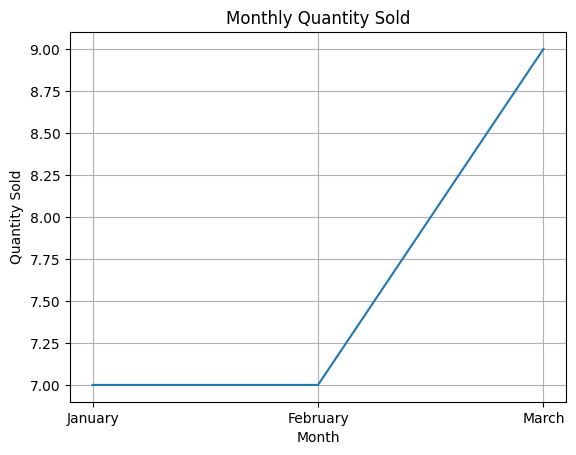

In [ ]:
# 1. Monthly quantity sold.
import matplotlib.pyplot as plt

monthly_quantity = sales.groupby("Month")["Quantity"].sum()

monthly_quantity = monthly_quantity.reindex(
    ["January", "February", "March"]
)

plt.plot(monthly_quantity.index, monthly_quantity.values)

plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.title("Monthly Quantity Sold")
plt.grid()
plt.show()

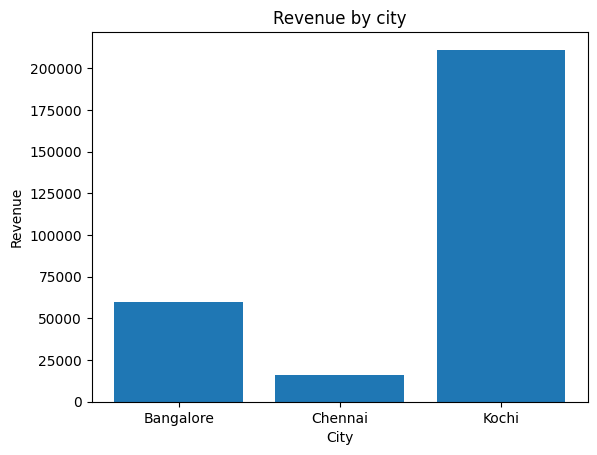

In [ ]:
# 2. Revenue by city.
city_sales = sales.groupby("City")["Revenue"].sum()

# monthly_quantity = monthly_quantity.reindex(
#     ["January", "February", "March"]
# )

plt.bar(city_sales.index, city_sales.values)

plt.xlabel("City")
plt.ylabel("Revenue")
plt.title("Revenue by city")

plt.show()


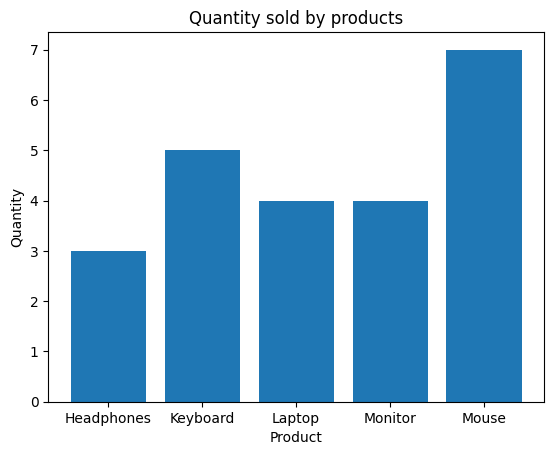

In [ ]:
# 3. Quantity sold by product.
product_quantity = sales.groupby("Product")["Quantity"].sum()

# monthly_quantity = monthly_quantity.reindex(
#     ["January", "February", "March"]
# )

plt.bar(product_quantity.index, product_quantity.values)

plt.xlabel("Product")
plt.ylabel("Quantity")
plt.title("Quantity sold by products")

plt.show()

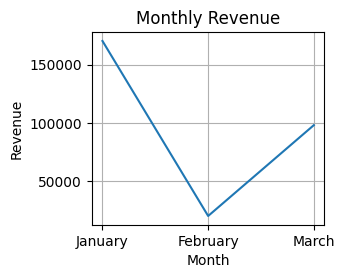

In [ ]:
# 4. Revenue by month

plt.figure(figsize=(3,2.5))
plt.plot(monthly_sales.index,monthly_sales.values) # plot used for line chart ( time series data )
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid()

plt.title("Monthly Revenue")
plt.show()

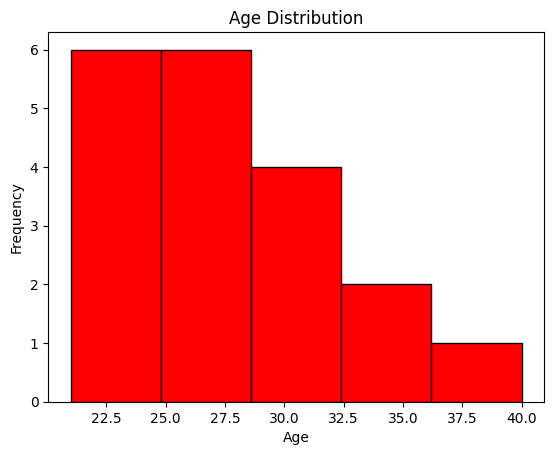

In [ ]:
import matplotlib.pyplot as plt

ages = [21, 22, 22, 23, 24,
        24, 25, 25, 26, 27,
        28, 28, 29, 30, 31,
        32, 35, 36, 40
        ]

plt.hist(ages, bins=5, edgecolor='black', color='red') # bins equally cuts into parts
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

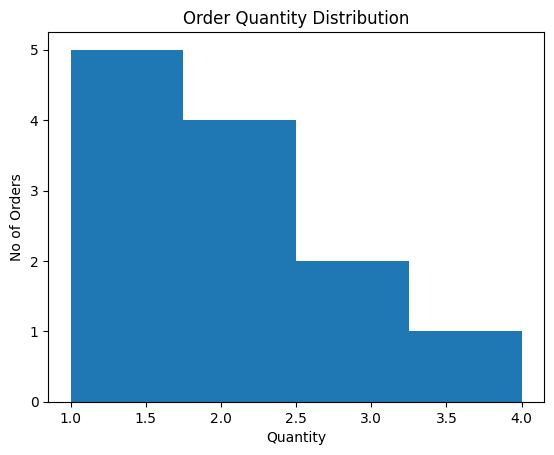

In [ ]:
plt.hist(
    sales["Quantity"],bins=4
)

plt.title("Order Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("No of Orders")
plt.show()

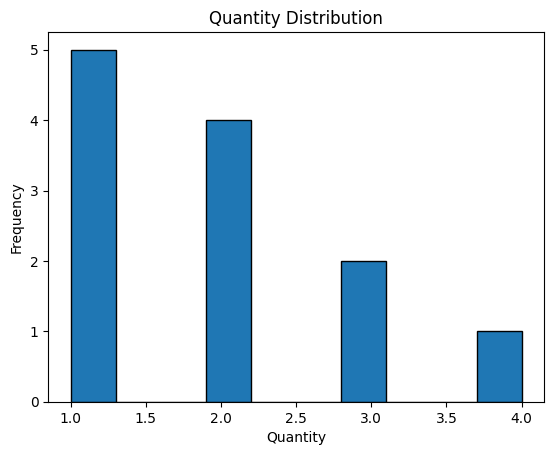

Min: 1
Max: 4
Average: 1.9166666666666667


In [ ]:
plt.hist(sales["Quantity"], edgecolor='black')
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

print("Min:", sales["Quantity"].min())      # 1
print("Max:", sales["Quantity"].max())      # 4
print("Average:", sales["Quantity"].mean()) # 1.92

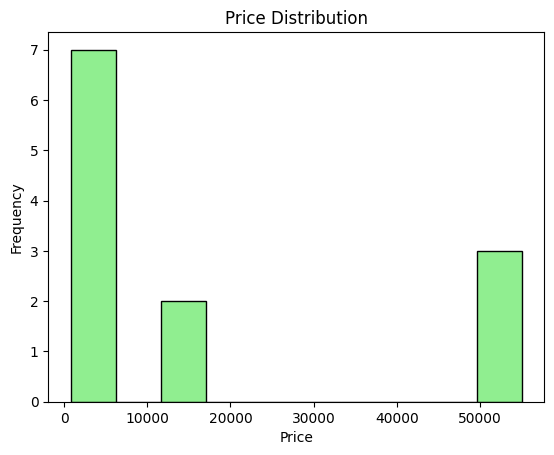

Min: 800
Max: 55000
Average: 16616.666666666668


In [ ]:
plt.hist(sales["Price"], edgecolor='black', color='lightgreen')
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

print("Min:", sales["Price"].min())      # 800
print("Max:", sales["Price"].max())      # 55000
print("Average:", sales["Price"].mean()) # 16616.67

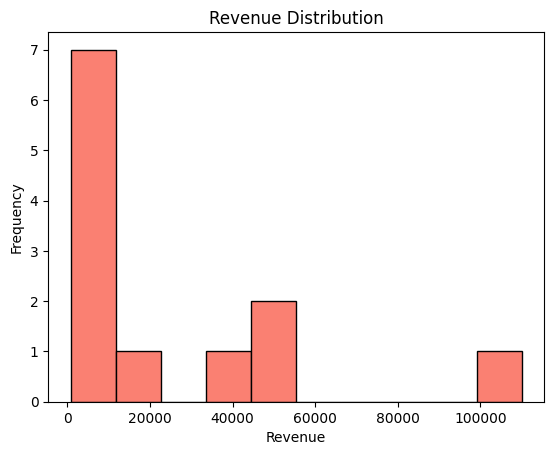

Min: 800
Max: 110000
Mean: 24050.0
Median: 4750.0


In [ ]:
plt.hist(sales["Revenue"], edgecolor='black', color='salmon')
plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

print("Min:", sales["Revenue"].min())        # 800
print("Max:", sales["Revenue"].max())        # 110000
print("Mean:", sales["Revenue"].mean())      # 24050.0
print("Median:", sales["Revenue"].median())  # 4750.0

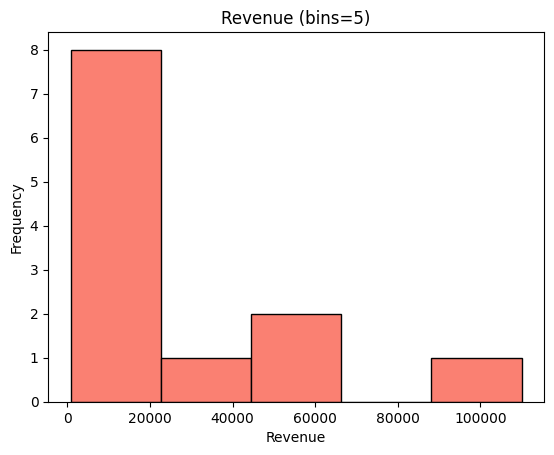

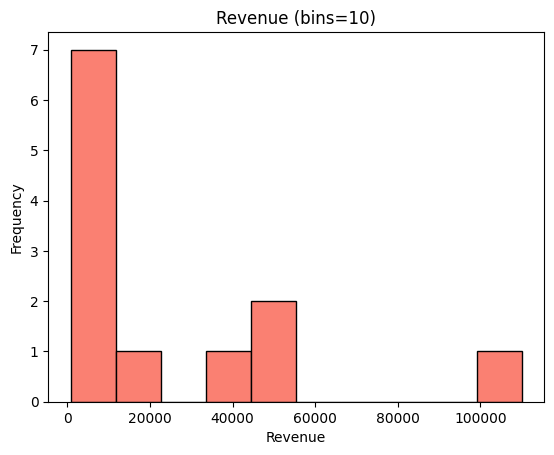

In [ ]:
plt.hist(sales["Revenue"], bins=5, edgecolor='black', color='salmon')
plt.title("Revenue (bins=5)")
plt.xlabel("Revenue"); plt.ylabel("Frequency")
plt.show()

plt.hist(sales["Revenue"], bins=10, edgecolor='black', color='salmon')
plt.title("Revenue (bins=10)")
plt.xlabel("Revenue"); plt.ylabel("Frequency")
plt.show()

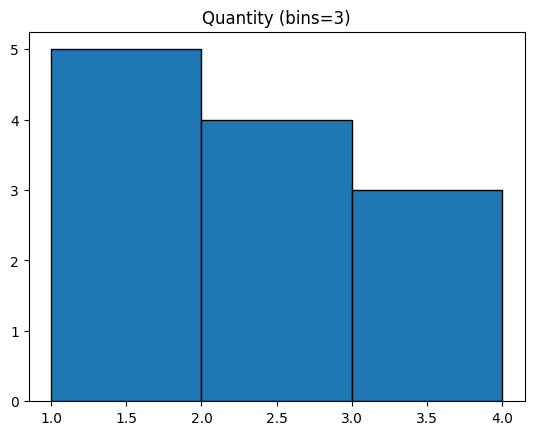

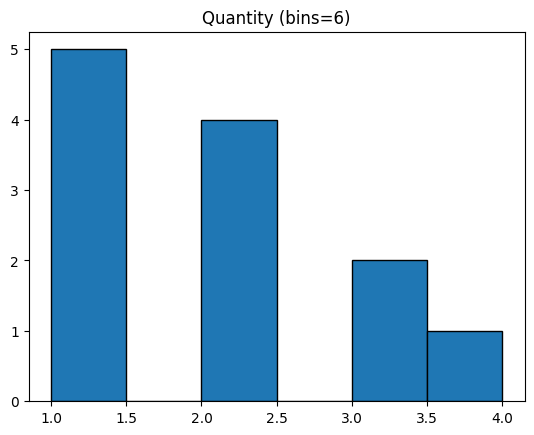

[2 1 3 4]


In [ ]:
plt.hist(sales["Quantity"], bins=3, edgecolor='black')
plt.title("Quantity (bins=3)")
plt.show()

plt.hist(sales["Quantity"], bins=6, edgecolor='black')
plt.title("Quantity (bins=6)")
plt.show()

print(sales["Quantity"].unique())   # [2 1 3 4]

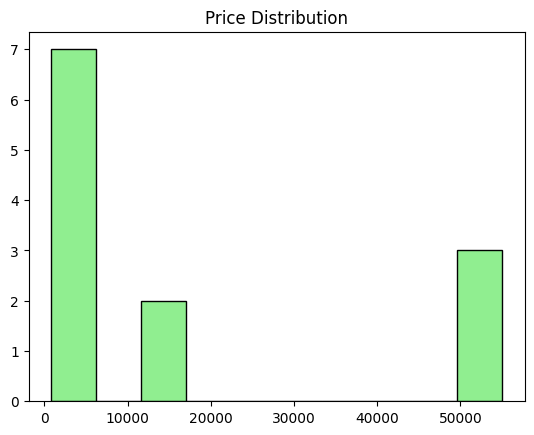

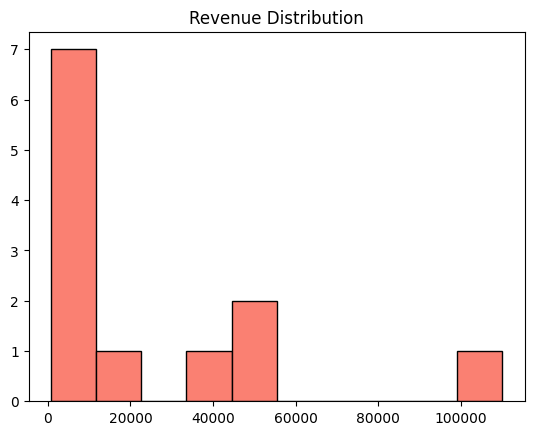

                    Price       Revenue
Category                               
Accessories   1485.714286   2942.857143
Electronics  37800.000000  53600.000000


In [ ]:
plt.hist(sales["Price"], edgecolor='black', color='lightgreen')
plt.title("Price Distribution")
plt.show()

plt.hist(sales["Revenue"], edgecolor='black', color='salmon')
plt.title("Revenue Distribution")
plt.show()

print(sales.groupby("Category")[["Price","Revenue"]].mean())

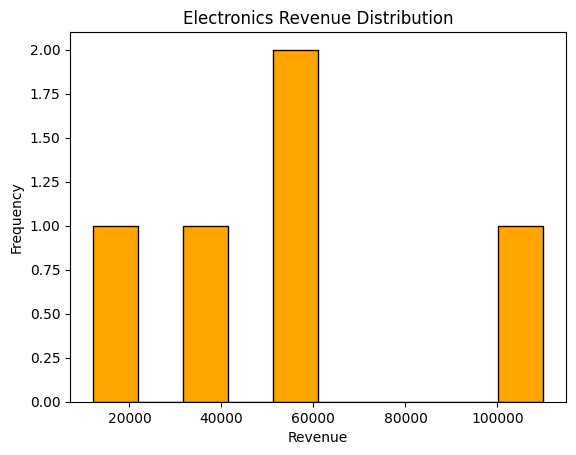

Total revenue: 268000
Average revenue: 53600.0


In [ ]:
electronics = sales[sales["Category"] == "Electronics"]

plt.hist(electronics["Revenue"], edgecolor='black', color='orange')
plt.title("Electronics Revenue Distribution")
plt.xlabel("Revenue"); plt.ylabel("Frequency")
plt.show()

print("Total revenue:", electronics["Revenue"].sum())     # 268000
print("Average revenue:", electronics["Revenue"].mean())  # 53600.0

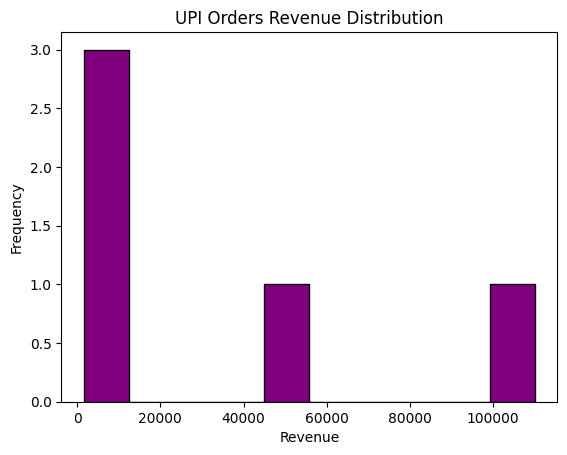

Number of UPI orders: 5
Total UPI revenue: 174300


In [ ]:
upi = sales[sales["Payment_Method"] == "UPI"]

plt.hist(upi["Revenue"], edgecolor='black', color='purple')
plt.title("UPI Orders Revenue Distribution")
plt.xlabel("Revenue"); plt.ylabel("Frequency")
plt.show()

print("Number of UPI orders:", upi.shape[0])       # 5
print("Total UPI revenue:", upi["Revenue"].sum())  # 174300

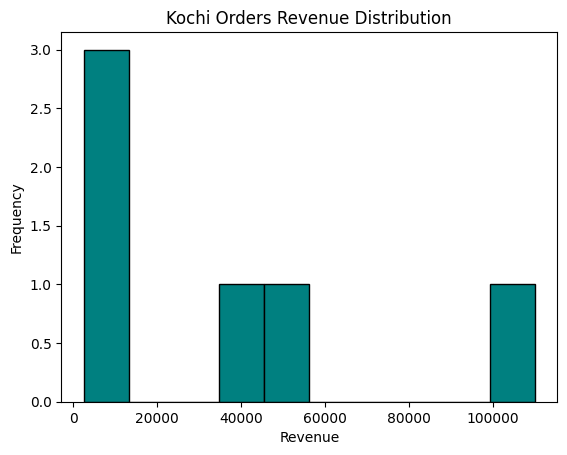

Total revenue: 211200
Average revenue: 35200.0


In [ ]:
kochi = sales[sales["City"] == "Kochi"]

plt.hist(kochi["Revenue"], edgecolor='black', color='teal')
plt.title("Kochi Orders Revenue Distribution")
plt.xlabel("Revenue"); plt.ylabel("Frequency")
plt.show()

print("Total revenue:", kochi["Revenue"].sum())     # 211200
print("Average revenue:", kochi["Revenue"].mean())  # 35200.0

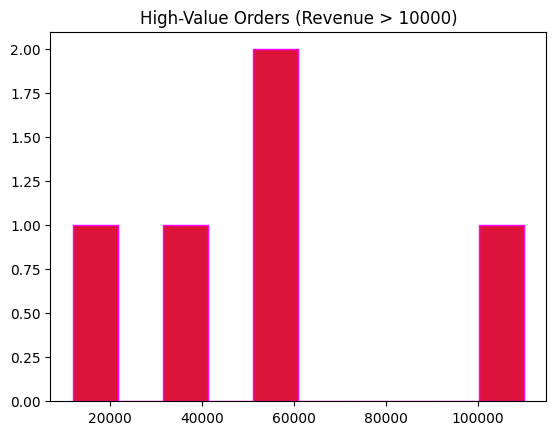

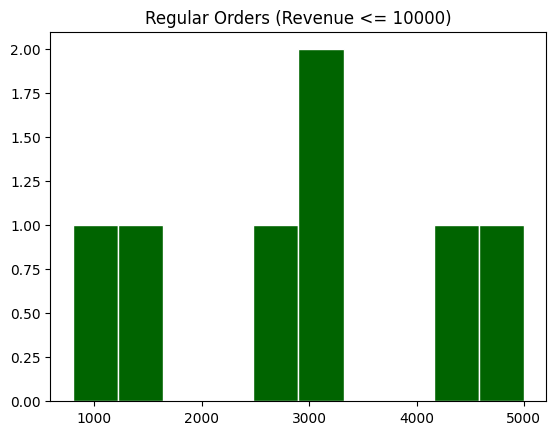

High-value count: 5
Regular count: 7


In [ ]:
high_value = sales[sales["Revenue"] > 10000]
regular = sales[sales["Revenue"] <= 10000]

plt.hist(high_value["Revenue"], edgecolor='magenta', color='crimson')
plt.title("High-Value Orders (Revenue > 10000)")
plt.show()

plt.hist(regular["Revenue"], edgecolor='white', color='darkgreen')
plt.title("Regular Orders (Revenue <= 10000)")
plt.show()

print("High-value count:", high_value.shape[0])   # 5
print("Regular count:", regular.shape[0])          # 7

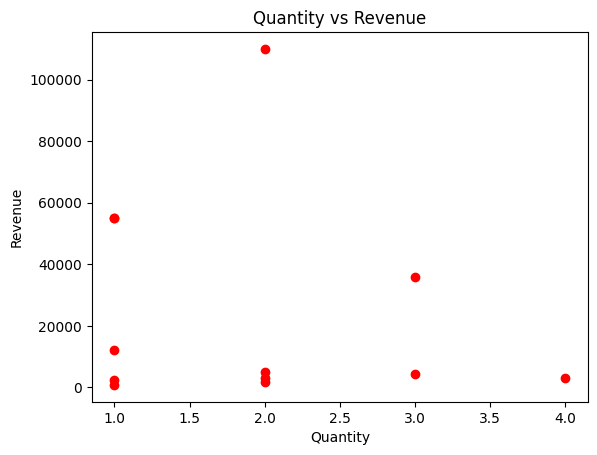

In [ ]:
# Scatter Plot - used to establish relationship between 2 values

plt.scatter(
    sales["Quantity"],
    sales["Revenue"],color='red'
)
plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.show()

In [ ]:
study_data = pd.DataFrame({
    "Study_Hours" : [1,2,2,3,3,
                     4,4,5,5,6,
                     6,7,7,8,9],
    "Exam_Score" : [
        42,48,51,55,60,
        63,66,70,73,76,
        79,82,85,89,93
    ]
})
study_data


,Study_Hours,Exam_Score
0,1,42
1,2,48
2,2,51
3,3,55
4,3,60
5,4,63
6,4,66
7,5,70
8,5,73
9,6,76


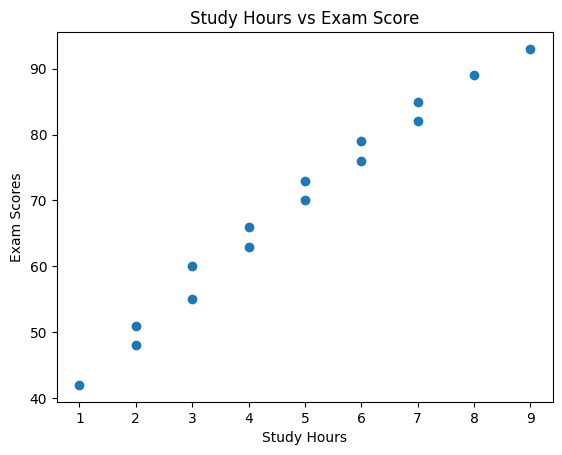

In [ ]:
plt.scatter(
    study_data["Study_Hours"],
    study_data["Exam_Score"]
)
plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Scores")
plt.show()

In [ ]:
# payment_method    |  No of Orders
payment_count = sales["Payment_Method"].value_counts() # instead of group by
payment_count

,count
Payment_Method,
UPI,5
Card,4
Cash,3


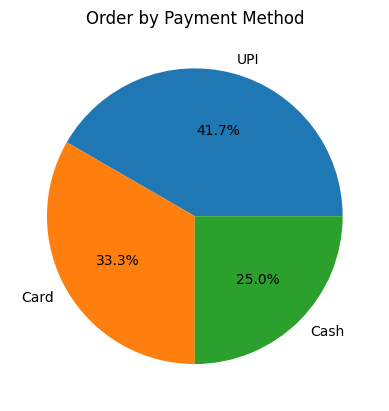

In [ ]:
plt.pie(
    payment_count.values,
    labels = payment_count.index,
    autopct="%1.1f%%"  # 1.1 floating point with percentage #autopct
)
plt.title("Order by Payment Method")
plt.show()

In [ ]:
# payment_count = sales["Payment_Method"].value_counts()

# explode = [0.05] * len(payment_count)   # slightly separates every slice

# plt.figure(figsize=(6,6))
# plt.pie(
#     payment_count.values,
#     labels=payment_count.index,
#     autopct="%1.1f%%",
#     shadow=True,           # ← adds the drop-shadow that creates a 3D illusion
#     explode=explode,       # ← separates slices for extra depth perception
#     startangle=90,
#     colors=['#ff9999','#66b3ff','#99ff99']
# )
# plt.title("Orders by Payment Method")
# plt.show()

In [ ]:
salary= [
    1000,
    1200,
    1500,
    1800,
    2000,
    2200,
    2500,
    3000,
    3500,
    50000
]

In [ ]:
sum(salary)/10

6870.0

In [ ]:
import matplotlib.pyplot as plt

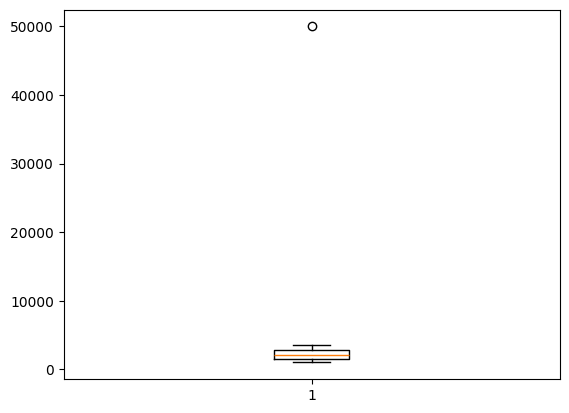

In [ ]:
plt.boxplot(salary) # potential outlier
plt.show()

In [ ]:
sales['Revenue']

,Revenue
0,110000
1,800
2,4500
3,55000
4,5000
5,3200
6,12000
7,3000
8,55000
9,36000


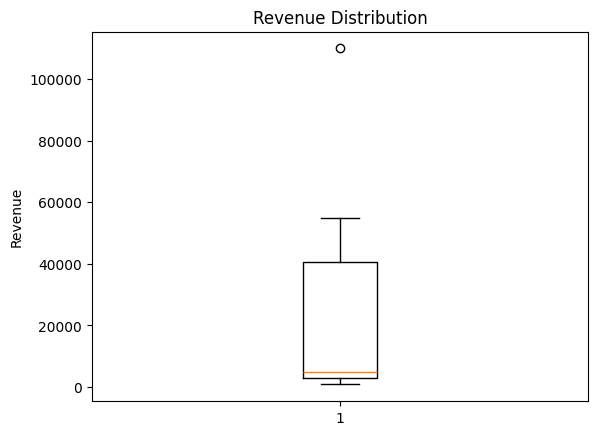

In [ ]:
plt.boxplot(sales["Revenue"])
plt.title("Revenue Distribution")
plt.ylabel("Revenue")
plt.show()


In [ ]:
sales["Revenue"].describe()



,Revenue
count,12.000000
mean,24050.000000
std,34009.504019
min,800.000000
25%,2875.000000
50%,4750.000000
75%,40750.000000
max,110000.000000


/tmp/ipykernel_1035/734587987.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


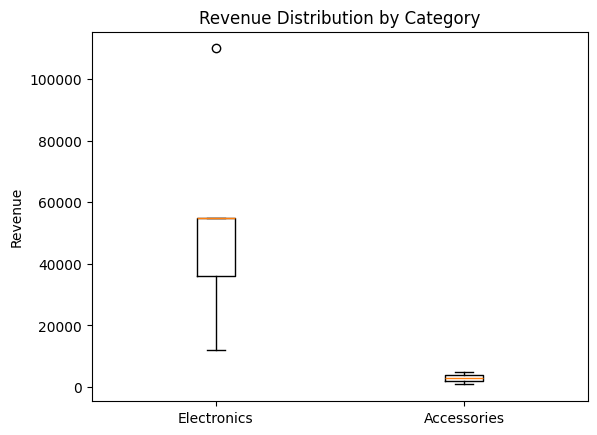

In [ ]:
plt.boxplot(
    [
        sales[sales['Category'] == "Electronics"]["Revenue"],
        sales[sales['Category'] == "Accessories"]["Revenue"]
    ],
    labels=["Electronics","Accessories"]
)
plt.title("Revenue Distribution by Category")
plt.ylabel("Revenue")
plt.show()

In [ ]:
sales[sales['Category'] == 'Accessories']

,Order_ID,Customer_ID,Product_ID,Order_Date,Quantity,Payment_Method,Name,City,Gender,Product,Category,Price,Revenue,Month
1,1002,102,P02,2026-01-08,1,Card,Meera,Chennai,Female,Mouse,Accessories,800,800,January
2,1003,101,P03,2026-01-15,3,UPI,Arun,Kochi,Male,Keyboard,Accessories,1500,4500,January
4,1005,104,P04,2026-02-03,2,Card,Anjali,Bangalore,Female,Headphones,Accessories,2500,5000,February
5,1006,105,P02,2026-02-10,4,UPI,Vivek,Kochi,Male,Mouse,Accessories,800,3200,February
7,1008,102,P03,2026-03-02,2,Card,Meera,Chennai,Female,Keyboard,Accessories,1500,3000,March
10,1011,109,P02,2026-03-20,2,UPI,NaN,NaN,NaN,Mouse,Accessories,800,1600,March
11,1012,103,P04,2026-03-25,1,Cash,Rahul,Kochi,Male,Headphones,Accessories,2500,2500,March


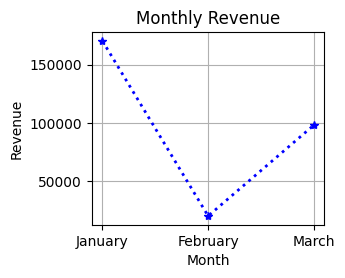

In [ ]:
monthly_sales = (sales.groupby("Month")["Revenue"].sum()
              .reindex(["January", "February", "March"]
))

plt.figure(figsize=(3,2.5))
plt.plot(monthly_sales.index
         ,monthly_sales.values,
         marker='*',
         linewidth= '2',
         linestyle=':',
         color='blue') # linewidth inbuilt 1 # plot used for line chart ( time series data )
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid()


plt.title("Monthly Revenue")
plt.show()

# marker = o - circle, ^ - triangle, s - square, * - star
# linestyle = : - dotted, -- - dashed

In [ ]:
electronics_sales = (
    sales[sales['Category'] == 'Electronics'].
    groupby('Month')['Revenue'].sum()
    .reindex(["January","February","March"])
)

accessories_sales = (
    sales[sales["Category"] == 'Accessories']
    .groupby("Month")["Revenue"].sum()
    .reindex(["January","February","March"])
)


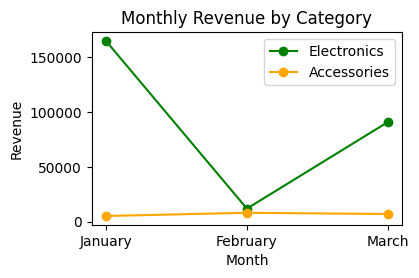

In [ ]:
plt.figure(figsize=(4,2.5))

plt.plot(
    electronics_sales.index,electronics_sales.values,
    marker='o',
    label="Electronics",
    color='green'
)

plt.plot(
    accessories_sales.index,accessories_sales.values,
    marker='o',
    label="Accessories",
    color='orange'
)


plt.title("Monthly Revenue by Category")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.legend()

plt.show()

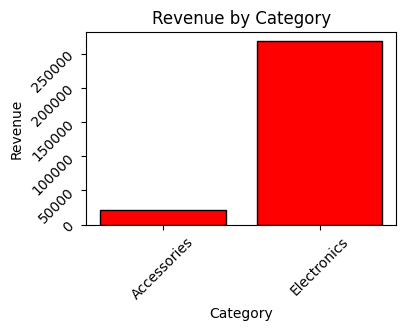

In [ ]:
category_sales = (
    sales.groupby("Category")["Revenue"].sum())
plt.figure(figsize=(4,2.5))
plt.bar(category_sales.index,category_sales.values,
        alpha=1,
        color='red',
        edgecolor='black')

plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.savefig("revenue_by_category.png")
plt.show()
# alpha is used to control the transparency of the color

In [ ]:
import pandas as pd

employees = pd.DataFrame({
    "Department": [
        "IT", "IT", "IT",
        "HR", "HR",
        "Finance", "Finance",
        "Marketing", "Marketing"
    ],
    "Salary": [
        30000, 42000, 55000,
        32000, 40000,
        45000, 60000,
        35000, 48000
    ],
    "Experience": [
        1, 4, 8,
        2, 5,
        4, 9,
        3, 6
    ]
})
employees

,Department,Salary,Experience
0,IT,30000,1
1,IT,42000,4
2,IT,55000,8
3,HR,32000,2
4,HR,40000,5
5,Finance,45000,4
6,Finance,60000,9
7,Marketing,35000,3
8,Marketing,48000,6


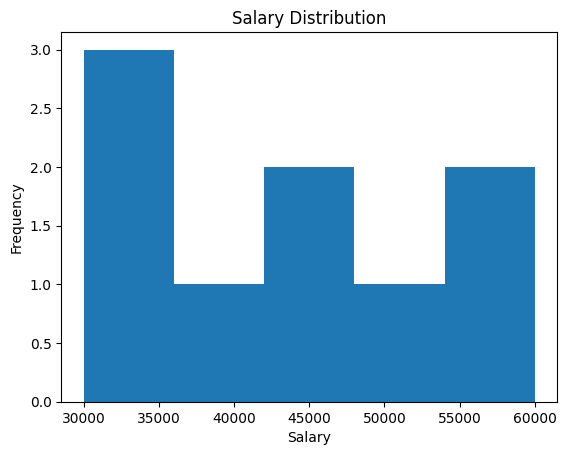

In [ ]:
import matplotlib.pyplot as plt

plt.hist(employees["Salary"],bins=5)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

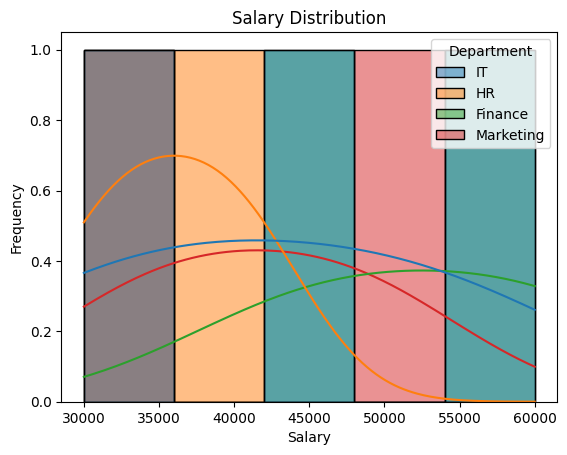

In [ ]:
import seaborn as sns
sns.histplot(data=employees,
             x="Salary",
             bins=5,
             kde=True,
             hue="Department",
             # hue
             ) # histplot used in seaborn for visualization

plt.title("Salary Distribution")
# plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()

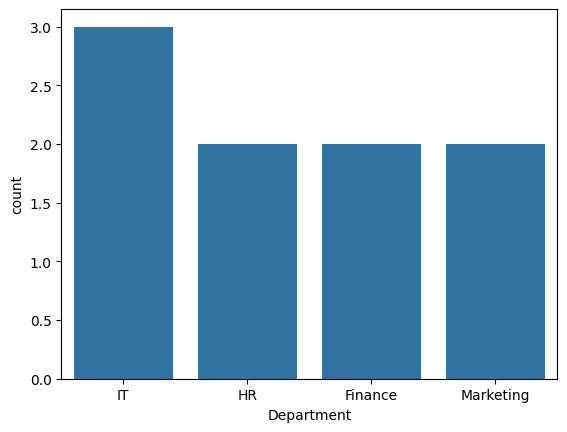

In [ ]:
sns.countplot(data=employees,
              x="Department",
              )
plt.show()

In [ ]:
employees["Gender"] = [
    "Male","Female","Male",
    "Female","Male","Male","Female",
    "Female","Male"
]
employees

,Department,Salary,Experience,Gender
0,IT,30000,1,Male
1,IT,42000,4,Female
2,IT,55000,8,Male
3,HR,32000,2,Female
4,HR,40000,5,Male
5,Finance,45000,4,Male
6,Finance,60000,9,Female
7,Marketing,35000,3,Female
8,Marketing,48000,6,Male


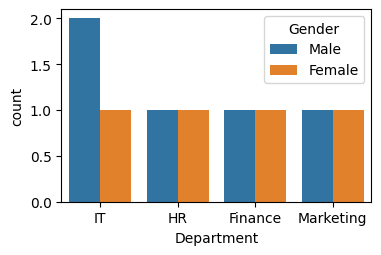

In [ ]:
plt.figure(figsize=(4,2.5))

sns.countplot(
    data=employees,
    x="Department",
    hue="Gender"
)
plt.show()

Department
Finance      52500.000000
HR           36000.000000
IT           42333.333333
Marketing    41500.000000
Name: Salary, dtype: float64


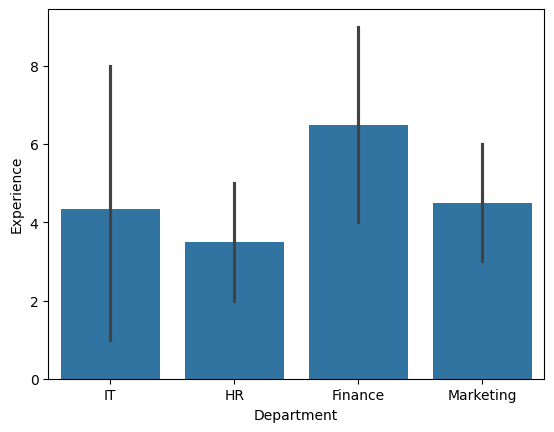

In [ ]:
print(employees.groupby("Department")["Salary"].mean())
sns.barplot(
    data = employees,
    x = "Department",
    y = "Experience"
)

plt.show() # black line conveys the range and the plotting blue colour mention the average

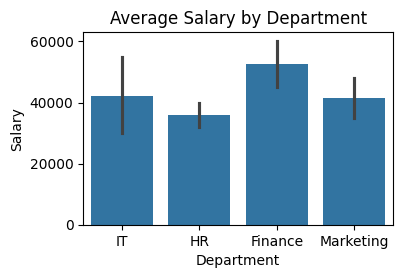

In [ ]:
# print(employees.groupby("Department")["Salary"].mean())
plt.figure(figsize=(4,2.5))
sns.barplot(
    data = employees,
    x = "Department",
    y = "Salary",
    estimator = "median"
)
plt.title("Average Salary by Department")
plt.show()
#boxplot is used for analyzing the distribution



Small Work

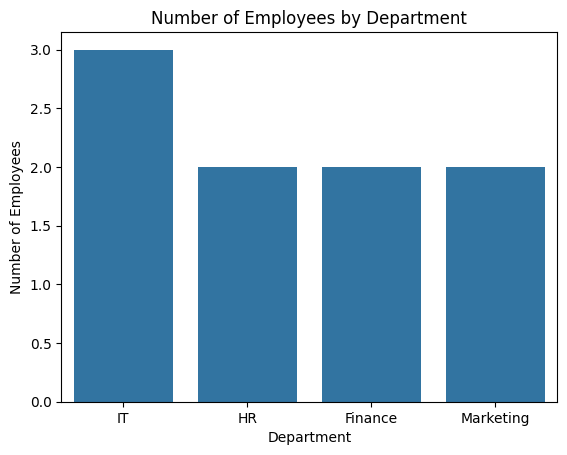

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    data=employees,
    x="Department",

)

plt.title("Number of Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.show()

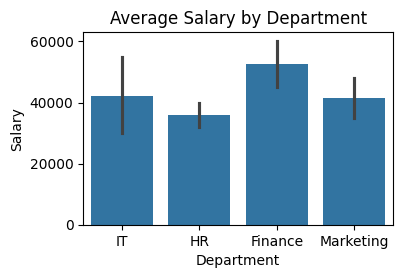

In [ ]:
plt.figure(figsize=(4,2.5))
sns.barplot(
    data = employees,
    x = "Department",
    y = "Salary",
    estimator = "median"
)
plt.title("Average Salary by Department")
plt.show()
#boxplot is used for analyzing the distribution


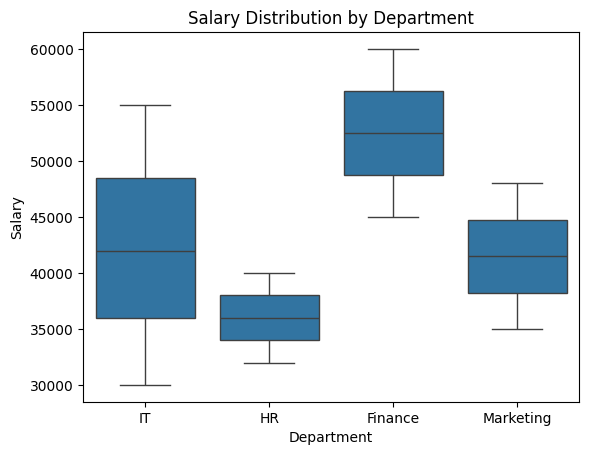

In [ ]:
sns.boxplot(
    data=employees,
    x="Department",
    y="Salary"
)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

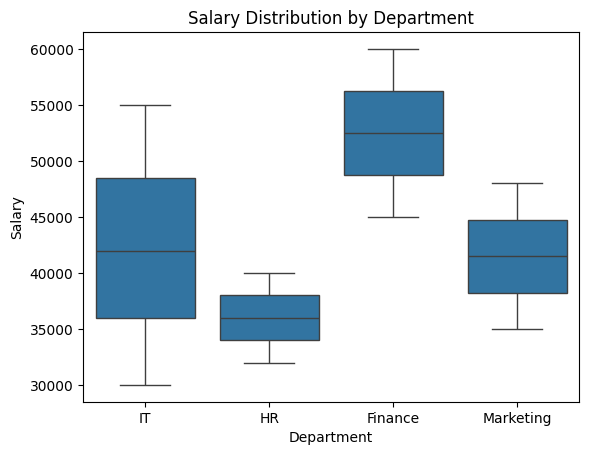

In [ ]:
sns.boxplot(
    data=employees,
    x="Department",
    y="Salary"
)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

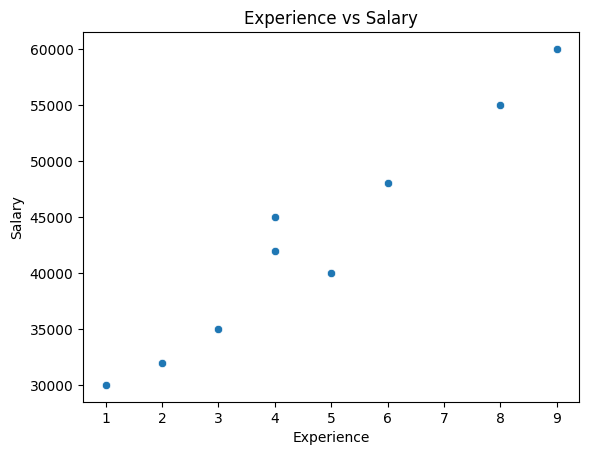

In [ ]:
sns.scatterplot(
    data=employees,
    x="Experience",
    y="Salary"
)

plt.title("Experience vs Salary")
plt.xlabel("Experience")
plt.ylabel("Salary")
plt.show()

In [ ]:
employees

,Department,Salary,Experience,Gender
0,IT,30000,1,Male
1,IT,42000,4,Female
2,IT,55000,8,Male
3,HR,32000,2,Female
4,HR,40000,5,Male
5,Finance,45000,4,Male
6,Finance,60000,9,Female
7,Marketing,35000,3,Female
8,Marketing,48000,6,Male


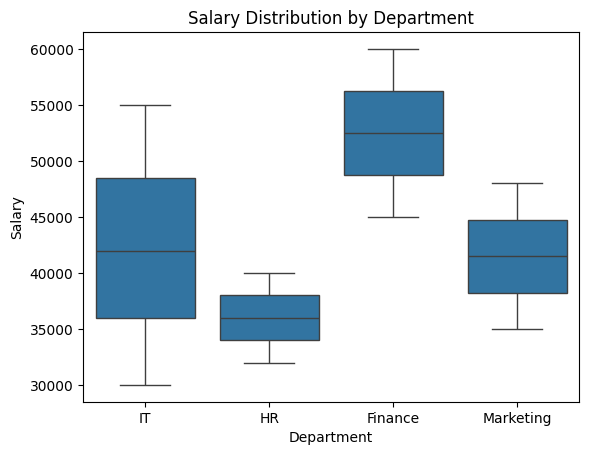

In [ ]:
sns.boxplot(
    data=employees,
    x="Department",
    y="Salary"
)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

In [ ]:
plt.figure

<function matplotlib.pyplot.figure(num: 'int | str | Figure | SubFigure | None' = None, figsize: 'tuple[float, float] | None' = None, dpi: 'float | None' = None, *, facecolor: 'ColorType | None' = None, edgecolor: 'ColorType | None' = None, frameon: 'bool' = True, FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>, clear: 'bool' = False, **kwargs) -> 'Figure'>

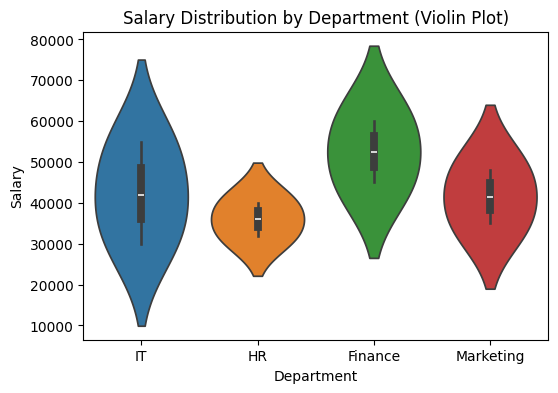

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.violinplot(
    data=employees,
    x="Department",
    y="Salary",
    hue="Department",
    legend=False
)

plt.title("Salary Distribution by Department (Violin Plot)")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

In [ ]:
import pandas as pd
students = pd.DataFrame({
    "Course" : ["Python","Python","Python",
                "DSML", "DSML","DSML",
                "Web","Web","Web"],
    "Marks" : [65,78,92,
               70,85,95,
               60,75,88]
})
students

,Course,Marks
0,Python,65
1,Python,78
2,Python,92
3,DSML,70
4,DSML,85
5,DSML,95
6,Web,60
7,Web,75
8,Web,88


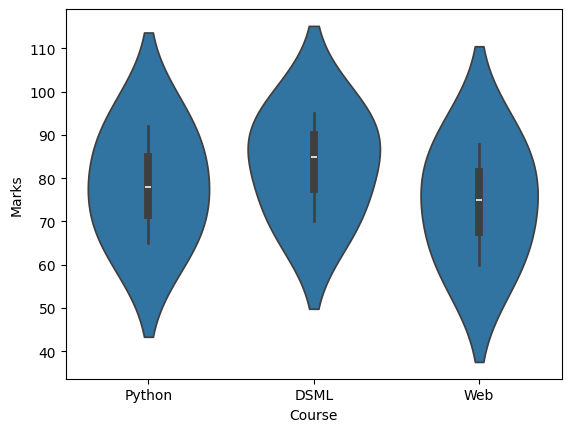

In [ ]:
sns.violinplot(
    data = students,
    x = "Course",
    y = "Marks"
)

plt.show()

In [ ]:
employees

,Department,Salary,Experience,Gender
0,IT,30000,1,Male
1,IT,42000,4,Female
2,IT,55000,8,Male
3,HR,32000,2,Female
4,HR,40000,5,Male
5,Finance,45000,4,Male
6,Finance,60000,9,Female
7,Marketing,35000,3,Female
8,Marketing,48000,6,Male


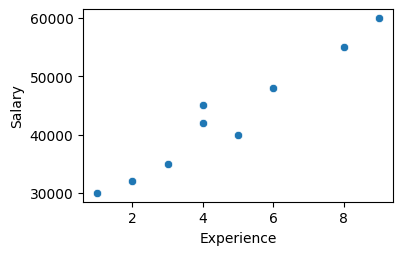

In [ ]:
plt.figure(figsize=(4,2.5))

sns.scatterplot(
    data = employees,
    x = "Experience",
    y = "Salary"
)

plt.show()

In [ ]:
numerical_data = employees[["Salary","Experience"]]

correlation = numerical_data.corr()
correlation

,Salary,Experience
Salary,1.000000,0.971767
Experience,0.971767,1.000000


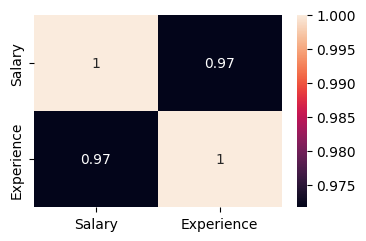

In [ ]:
plt.figure(figsize=(4,2.5))

sns.heatmap(
    correlation,
    annot=True
)
plt.show()

In [ ]:
students = pd.DataFrame({
    "Study_Hours" : [2,3,4,5,6,7,8,9],
    "Attendance" : [65,70,72,78,82,88,91,95],
    "Assignment_Score" : [55,60,65,72,78,84,89,94],
    "Final_Mark" : [50,58,64,70,76,83,88,95],
})
students["Performance"] = [
    "Low", "Low", "Medium", "Medium", "High", "High"
]




ValueError: Length of values (6) does not match length of index (8)

<Figure size 400x250 with 0 Axes>

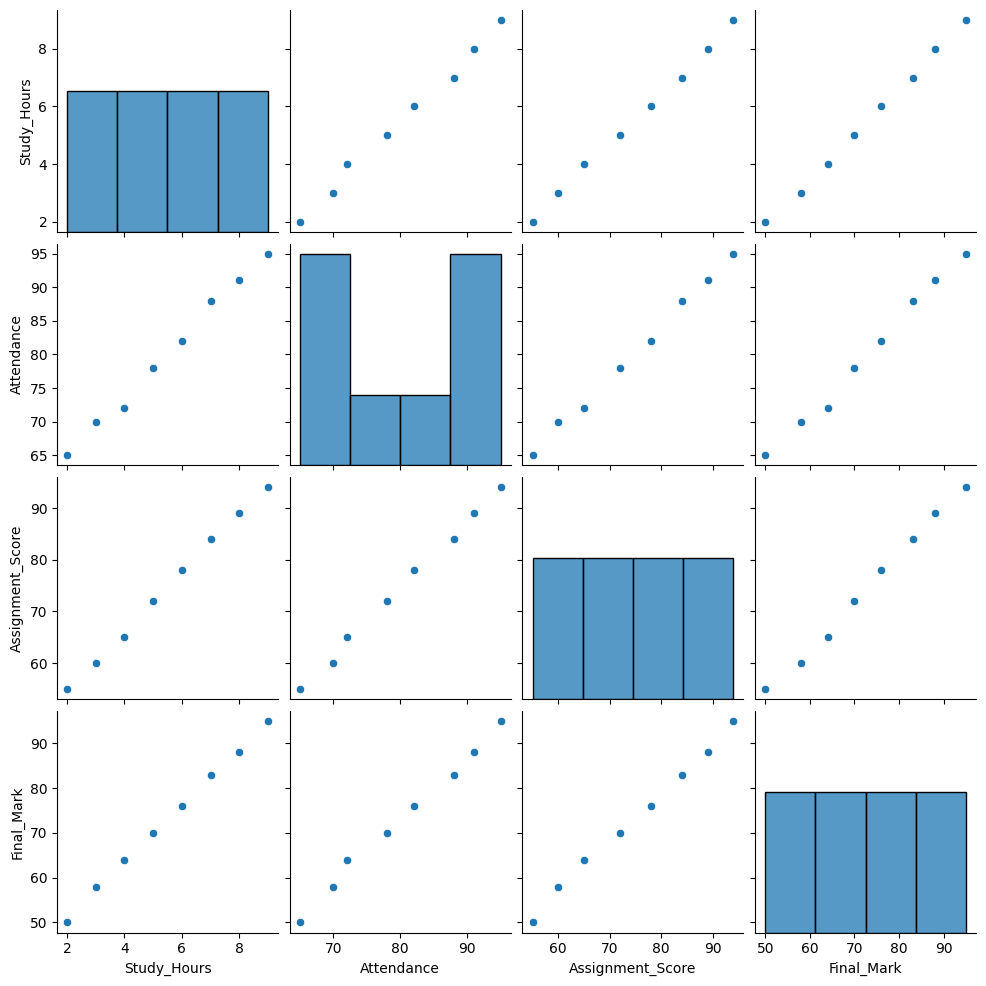

In [ ]:
plt.figure(figsize=(4,2.5))
sns.pairplot(students)
plt.show()

In [ ]:


plt.figure(figsize = (4,2.5))
sns.pairplot(stduents,hue="Performance")

ValueError: Length of values (6) does not match length of index (8)

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sales = pd.DataFrame({
    "Month": [
        "Jan", "Feb", "Mar", "Apr",
        "Jan", "Feb", "Mar", "Apr",
        "Jan", "Feb", "Mar", "Apr"
    ],

    "Product": [
        "Laptop", "Laptop", "Laptop", "Laptop",
        "Mobile", "Mobile", "Mobile", "Mobile",
        "Tablet", "Tablet", "Tablet", "Tablet"
    ],

    "Sales": [
        55000, 62000, 70000, 78000,
        45000, 52000, 49000, 60000,
        30000, 35000, 32000, 34000
    ]
})

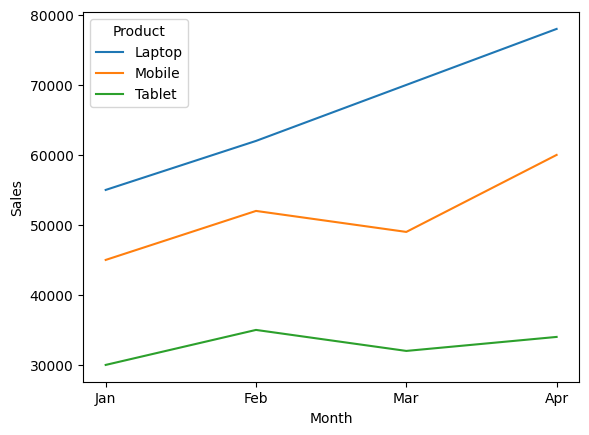

In [ ]:
sns.lineplot(data= sales,
             x="Month",
             y = "Sales",
             hue = "Product"
             )
plt.show()

In [ ]:
sales["Product"].unique()

array(['Laptop', 'Mobile', 'Tablet'], dtype=object)

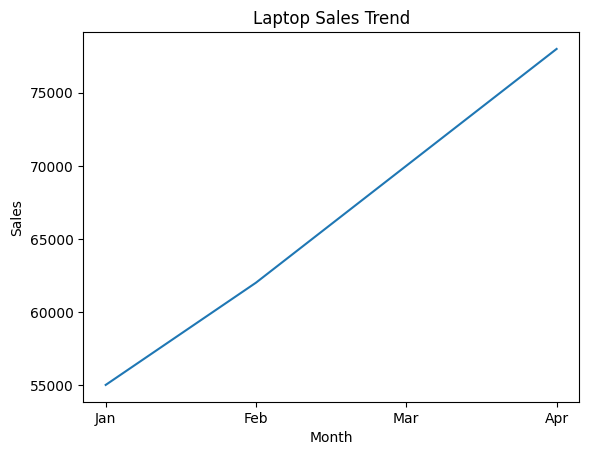

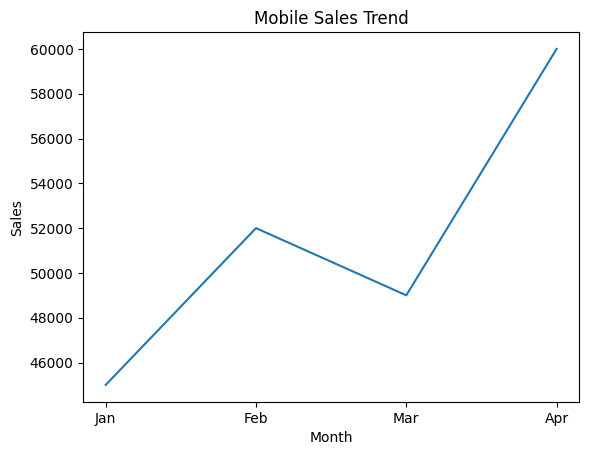

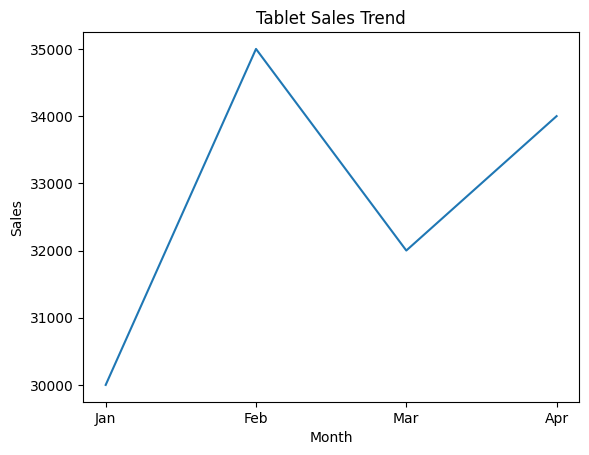

In [ ]:
for product in sales['Product'].unique():
  # print(product)
  product_data = sales[
      sales['Product'] == product
  ]
  # print(product_data)
  # print('='*10)
  sns.lineplot(data = product_data,
               x="Month",
               y="Sales")
  plt.title(f"{product} Sales Trend")
  plt.show()